# Clasificación de tumores de mama: KNN, SVM y MLP

**Fundamentos de Inteligencia Artificial**, grupo LITIID71, Equipo ClimateAI.

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/HectorPartido/Tumores-KNN-SVM-MLP/blob/main/Clasificacion_Tumores_KNN_SVM_MLP.ipynb)

Comparamos tres clasificadores supervisados (K vecinos más cercanos, máquina de vectores de soporte y perceptrón multicapa) para decidir si un tumor de mama es **benigno** o **maligno** a partir de 30 características de los núcleos celulares. Los tres se entrenan con los mismos datos de entrenamiento y se evalúan con el mismo conjunto de prueba, con exactitud, precisión, exhaustividad (recall), F1 y matriz de confusión.

**Datos:** Wisconsin Diagnostic Breast Cancer (WDBC), Universidad de Wisconsin, 1995: 569 tumores (357 benignos y 212 malignos) y 30 características numéricas calculadas de imágenes de una punción con aguja fina. Los archivos `wdbc.data` y `wdbc.names` están en la carpeta `data/` del repositorio.

| Sección | Contenido | Responsable |
|---|---|---|
| 1 y 2 | Carga, exploración y preparación de los datos | Hector Martínez Sánchez |
| 3 | K vecinos más cercanos (KNN) | Ismael Alexander Hidalgo Aguilando |
| 4 | Máquina de vectores de soporte (SVM) | Gildardo Emmanuel González García |
| 5 | Perceptrón multicapa (MLP) | Anthony Oziel Ramos López |
| 6 a 8 | Comparación, respuestas a las preguntas y conclusión | Hector Partido Flores |


## 1. Carga y exploración de los datos

**Responsable:** Hector Martínez Sánchez

Cada fila es un tumor. Las columnas son el identificador, el diagnóstico (`M` maligno o `B` benigno) y 30 características: 10 medidas del núcleo celular (radio, textura, perímetro, área, suavidad, compacidad, concavidad, puntos cóncavos, simetría y dimensión fractal), cada una como **media**, **error estándar** y **peor valor** (promedio de los 3 más grandes), según `wdbc.names`.

In [1]:
import time
from pathlib import Path
from urllib.request import urlretrieve

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import (accuracy_score, confusion_matrix, ConfusionMatrixDisplay, f1_score,
                             precision_score, recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

SEMILLA = 42                      # misma semilla en todo el notebook para que los resultados se repitan
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.precision", 3)

In [2]:
# Nombres de las 30 características (orden de wdbc.names): 10 medidas x (media, error estándar, peor valor)
MEDIDAS = ["radio", "textura", "perimetro", "area", "suavidad", "compacidad",
           "concavidad", "puntos_concavos", "simetria", "dimension_fractal"]
CARACTERISTICAS = [f"{m}_{tipo}" for tipo in ("media", "ee", "peor") for m in MEDIDAS]
COLUMNAS = ["id", "diagnostico"] + CARACTERISTICAS

# Se lee data/wdbc.data; en Colab se descarga del repositorio de GitHub
RUTA = Path("data/wdbc.data")
URL = "https://raw.githubusercontent.com/HectorPartido/Tumores-KNN-SVM-MLP/main/data/wdbc.data"
if not RUTA.exists():
    RUTA.parent.mkdir(parents=True, exist_ok=True)
    urlretrieve(URL, RUTA)

datos = pd.read_csv(RUTA, header=None, names=COLUMNAS)
print(f"Filas: {datos.shape[0]}, columnas: {datos.shape[1]}")
datos.head()

Filas: 569, columnas: 32


,id,diagnostico,radio_media,textura_media,perimetro_media,area_media,suavidad_media,compacidad_media,concavidad_media,puntos_concavos_media,...,radio_peor,textura_peor,perimetro_peor,area_peor,suavidad_peor,compacidad_peor,concavidad_peor,puntos_concavos_peor,simetria_peor,dimension_fractal_peor
0,842302,M,17.99,10.38,122.80,1001.0,0.118,0.278,0.300,0.147,...,25.38,17.33,184.60,2019.0,0.162,0.666,0.712,0.265,0.460,0.119
1,842517,M,20.57,17.77,132.90,1326.0,0.085,0.079,0.087,0.070,...,24.99,23.41,158.80,1956.0,0.124,0.187,0.242,0.186,0.275,0.089
2,84300903,M,19.69,21.25,130.00,1203.0,0.110,0.160,0.197,0.128,...,23.57,25.53,152.50,1709.0,0.144,0.424,0.450,0.243,0.361,0.088
3,84348301,M,11.42,20.38,77.58,386.1,0.142,0.284,0.241,0.105,...,14.91,26.50,98.87,567.7,0.210,0.866,0.687,0.258,0.664,0.173
4,84358402,M,20.29,14.34,135.10,1297.0,0.100,0.133,0.198,0.104,...,22.54,16.67,152.20,1575.0,0.137,0.205,0.400,0.163,0.236,0.077


In [3]:
print("Valores faltantes:", int(datos.isna().sum().sum()))
print("Identificadores repetidos:", int(datos["id"].duplicated().sum()))
conteo = datos["diagnostico"].map({"B": "Benigno", "M": "Maligno"}).value_counts()
print(pd.DataFrame({"tumores": conteo, "porcentaje": (100 * conteo / len(datos)).round(1)}))
datos[["radio_media", "textura_media", "area_media", "suavidad_media", "area_peor"]].describe().T

Valores faltantes: 0
Identificadores repetidos: 0
             tumores  porcentaje
diagnostico                     
Benigno          357        62.7
Maligno          212        37.3


,count,mean,std,min,25%,50%,75%,max
radio_media,569.0,14.127,3.524,6.981,11.700,13.370,15.780,28.110
textura_media,569.0,19.290,4.301,9.710,16.170,18.840,21.800,39.280
area_media,569.0,654.889,351.914,143.500,420.300,551.100,782.700,2501.000
suavidad_media,569.0,0.096,0.014,0.053,0.086,0.096,0.105,0.163
area_peor,569.0,880.583,569.357,185.200,515.300,686.500,1084.000,4254.000


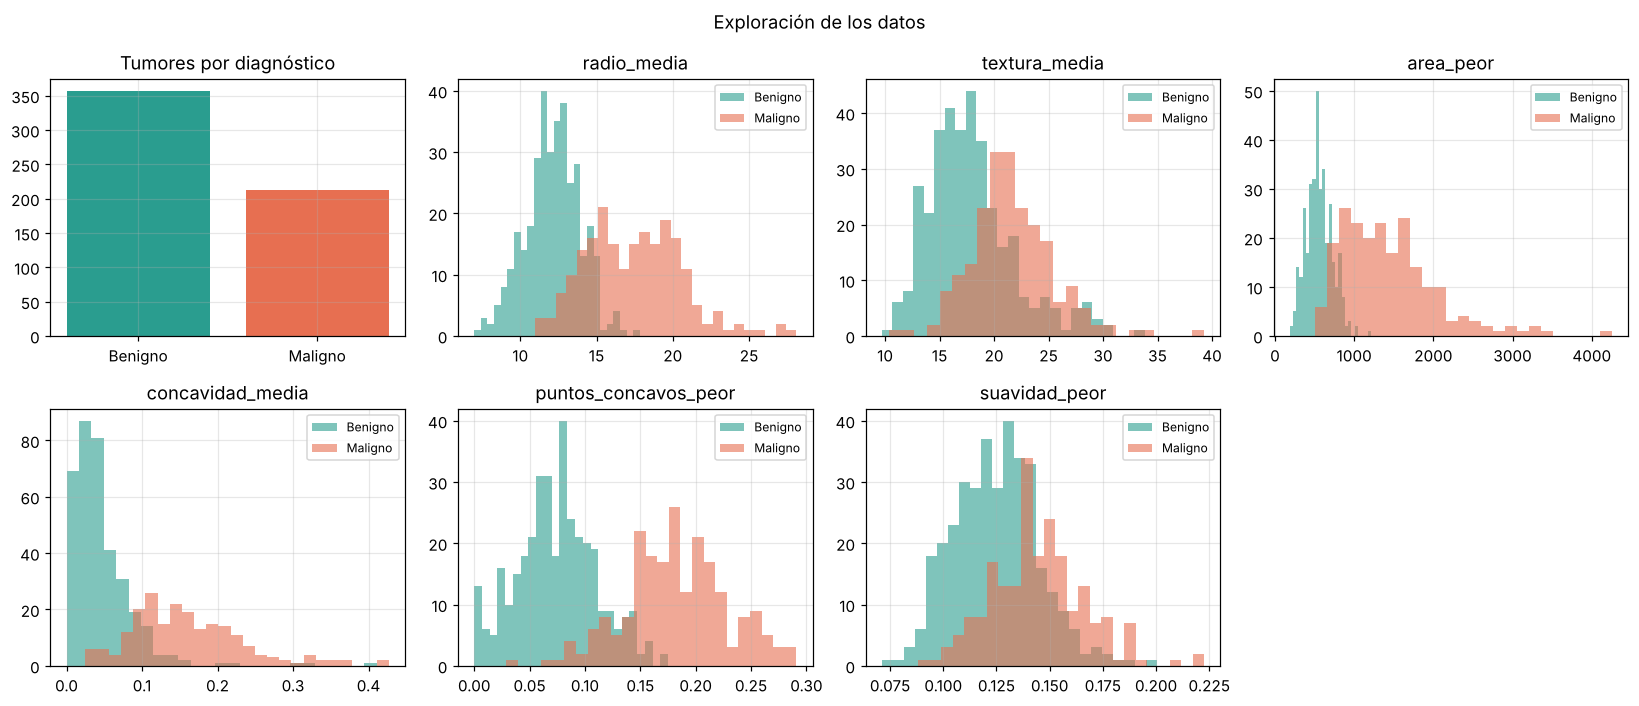

In [4]:
# Distribución de clases y 6 características por diagnóstico
VARIABLES = ["radio_media", "textura_media", "area_peor", "concavidad_media", "puntos_concavos_peor", "suavidad_peor"]
COLORES = {"B": "#2a9d8f", "M": "#e76f51"}
fig, ejes = plt.subplots(2, 4, figsize=(15, 6.5))
ejes = ejes.ravel()
ejes[0].bar(["Benigno", "Maligno"], [conteo["Benigno"], conteo["Maligno"]], color=[COLORES["B"], COLORES["M"]])
ejes[0].set_title("Tumores por diagnóstico")
for eje, var in zip(ejes[1:], VARIABLES):
    for clase, nombre in (("B", "Benigno"), ("M", "Maligno")):
        eje.hist(datos.loc[datos["diagnostico"] == clase, var], bins=25, alpha=0.6, color=COLORES[clase], label=nombre)
    eje.set_title(var)
    eje.legend(fontsize=8)
ejes[-1].axis("off")
fig.suptitle("Exploración de los datos")
fig.tight_layout()
plt.show()

**Resumen del conjunto de datos:**

- **Registros:** 569 tumores.
- **Variables:** 32 columnas. `id` solo identifica al tumor y no se usa para predecir; `diagnostico` es la **variable objetivo**; las otras 30 son las **características de entrada**, todas numéricas.
- **Clases a predecir:** benigno (`B`, 357 tumores) y maligno (`M`, 212 tumores). Es una clasificación binaria.

**Observaciones:**

- No hay valores faltantes ni tumores repetidos.
- Las clases no están equilibradas (63 % benignos y 37 % malignos), así que la partición debe ser **estratificada** para conservar esa proporción en entrenamiento y en prueba.
- Las escalas son muy distintas (el área va de cientos a miles y la suavidad de 0.05 a 0.2). KNN, SVM y MLP usan distancias o gradientes, por eso hay que **estandarizar**.
- Varias características separan bien las clases (el peor valor del área y de los puntos cóncavos casi no se traslapan), lo que anticipa una exactitud alta.

## 2. Preparación de los datos

**Responsable:** Hector Martínez Sánchez

- **Variable objetivo:** maligno = 1 y benigno = 0. La clase positiva es **maligno**: precisión, exhaustividad y F1 se calculan sobre ella.
- **Partición:** 80 % entrenamiento y 20 % prueba, estratificada y con `random_state = 42`. El conjunto de prueba no se toca hasta evaluar.
- **Estandarización:** cada modelo es un `Pipeline` con `StandardScaler`. Así la media y la desviación se calculan solo con entrenamiento (y en cada pliegue de la validación cruzada), sin filtrar información de prueba.
- **Ajuste de hiperparámetros:** `GridSearchCV` con validación cruzada estratificada de 5 pliegues sobre entrenamiento, optimizando **F1**, que equilibra no dejar pasar malignos (exhaustividad) y no alarmar de más (precisión).

In [5]:
X = datos[CARACTERISTICAS]
y = (datos["diagnostico"] == "M").astype(int)          # 1 = maligno, 0 = benigno

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEMILLA)

VALIDACION = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)

print(f"Entrenamiento: {len(X_train)} tumores ({y_train.mean():.1%} malignos)")
print(f"Prueba:        {len(X_test)} tumores ({y_test.mean():.1%} malignos)")

Entrenamiento: 455 tumores (37.4% malignos)
Prueba:        114 tumores (36.8% malignos)


In [6]:
# Evaluación común para los 3 modelos: todos se miden igual y con el mismo conjunto de prueba
resultados = {}


def evaluar(nombre, busqueda, segundos_ajuste):
    """Mide el mejor modelo de la búsqueda en prueba, guarda sus métricas y dibuja su matriz de confusión."""
    modelo = busqueda.best_estimator_
    inicio = time.perf_counter()
    y_pred = modelo.predict(X_test)
    milisegundos = (time.perf_counter() - inicio) * 1000
    matriz = confusion_matrix(y_test, y_pred)
    # KNN y MLP dan probabilidad de maligno; la SVM da la distancia a la frontera (sirve igual para el AUC)
    puntaje = modelo.predict_proba(X_test)[:, 1] if hasattr(modelo, "predict_proba") else modelo.decision_function(X_test)
    resultados[nombre] = {
        "modelo": modelo,
        "mejores_hiperparametros": busqueda.best_params_,
        "F1 validación cruzada": busqueda.best_score_,
        "Exactitud entrenamiento": accuracy_score(y_train, modelo.predict(X_train)),
        "Exactitud": accuracy_score(y_test, y_pred),
        "Precisión": precision_score(y_test, y_pred),
        "Exhaustividad": recall_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
        "AUC": roc_auc_score(y_test, puntaje),
        "puntaje": puntaje,
        "Malignos no detectados (FN)": int(matriz[1, 0]),
        "Benignos marcados como malignos (FP)": int(matriz[0, 1]),
        "Ajuste (s)": segundos_ajuste,
        "Predicción de prueba (ms)": milisegundos,
    }
    r = resultados[nombre]
    print(f"Mejores hiperparámetros: {busqueda.best_params_}")
    print(f"F1 en validación cruzada: {r['F1 validación cruzada']:.3f}")
    print(f"Exactitud: entrenamiento {r['Exactitud entrenamiento']:.3f}, prueba {r['Exactitud']:.3f}")
    print(f"Precisión {r['Precisión']:.3f} | Exhaustividad {r['Exhaustividad']:.3f} | F1 {r['F1']:.3f}")
    print(f"Tiempo: ajuste {segundos_ajuste:.2f} s, predicción de {len(X_test)} tumores {milisegundos:.1f} ms")
    ConfusionMatrixDisplay(matriz, display_labels=["Benigno", "Maligno"]).plot(cmap="Blues", colorbar=False)
    plt.title(f"Matriz de confusión: {nombre} (prueba)")
    plt.xlabel("Diagnóstico que da el modelo")
    plt.ylabel("Diagnóstico real")
    plt.grid(False)
    plt.show()
    return r